# 01 — EDA & Vintage Analysis (CreditRisk-IFRS9)

**Purpose.** Before any model, look at the portfolio: how big is it, how does
delinquency evolve by origination cohort (vintage), and is the grade ranking
monotone in realised defaults?

**Data.** Synthetic loans generated by `src/generate_synthetic.py`
(`data/synthetic/loans.csv`, `data/synthetic/snapshots.csv`) — 20,000 loans,
2022-01 to 2025-06. All numbers below are **illustrative**, from synthetic data.
Run the pipeline first if the files do not exist: `python -m src.run_pipeline`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

loans = pd.read_csv("../data/synthetic/loans.csv")
snaps = pd.read_csv("../data/synthetic/snapshots.csv")
print(f"loans: {len(loans):,} | snapshots: {len(snaps):,}")
print(f"12-month default rate: {loans['default_12m'].mean():.2%}")
loans.head()

loans: 20,000 | snapshots: 500,000
12-month default rate: 10.08%


,loan_id,origination_month,grade,term_months,loan_amnt,int_rate,annual_income,dti,revol_util,bureau_score,emp_length_years,delinq_2yrs,purpose,pd_latent,default_12m,months_to_default,lgd_realised
0,1,2022-04,B,36,10319.69,0.1099,19521.23,36.75,56.45,736,5,0,credit_card,0.0885,0,NaN,NaN
1,2,2024-09,D,36,11214.74,0.1571,102421.43,42.34,41.16,677,0,0,home_improvement,0.2313,0,NaN,NaN
2,3,2024-04,E,60,6603.71,0.2317,105407.30,26.37,22.20,650,8,1,debt_consolidation,0.1128,0,NaN,NaN
3,4,2023-07,E,36,14677.08,0.2197,42369.61,21.04,38.65,638,2,1,other,0.1356,1,5.0,0.4387
4,5,2023-07,D,36,12770.00,0.1633,73261.48,19.94,62.06,680,11,1,credit_card,0.0749,0,NaN,NaN


In [2]:
# Default rate by grade — must be monotone (A safest, G riskiest)
by_grade = (loans.groupby("grade")["default_12m"]
            .agg(["count", "mean"]).rename(columns={"mean": "default_rate"}))
by_grade["default_rate_pct"] = (by_grade["default_rate"] * 100).round(2)
by_grade

,count,default_rate,default_rate_pct
grade,,,
A,2187,0.055327,5.53
B,2672,0.071856,7.19
C,3889,0.087683,8.77
D,4134,0.102806,10.28
E,3501,0.116252,11.63
F,2144,0.141325,14.13
G,1473,0.154107,15.41


In [3]:
# Vintage curves: % in 90+ DPD by months on book (MOB), first vintages
piv = (snaps.assign(is90=(snaps["dpd_bucket"] == "90+"))
       .groupby(["origination_month", "months_on_book"])["is90"].mean()
       .unstack("months_on_book") * 100)
piv.loc[["2022-01", "2022-02", "2022-03", "2023-01", "2024-01"], [3, 6, 9, 12, 18, 24]].round(2)

months_on_book,3,6,9,12,18,24
origination_month,,,,,,
2022-01,1.02,4.29,8.38,12.27,12.27,12.68
2022-02,1.18,3.73,6.88,10.02,10.22,10.22
2022-03,1.07,4.70,8.12,10.68,11.11,11.11
2023-01,0.20,3.46,7.32,10.37,11.38,10.16
2024-01,0.21,3.00,7.73,11.80,12.02,11.80


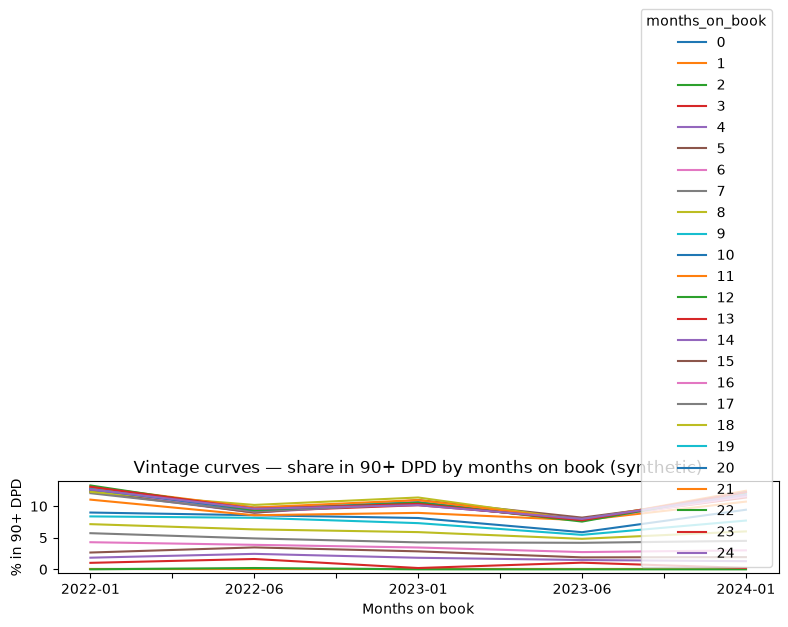

In [4]:
# Plot: vintage curves (90+ DPD vs MOB) — curves rise then flatten
ax = piv.loc[["2022-01", "2022-06", "2023-01", "2023-06", "2024-01"]].plot(figsize=(8, 4))
ax.set_xlabel("Months on book"); ax.set_ylabel("% in 90+ DPD")
ax.set_title("Vintage curves — share in 90+ DPD by months on book (synthetic)")
plt.tight_layout(); plt.show()

In [5]:
# Roll rates, pandas cross-check of sql/02_roll_rates.sql
snaps_sorted = snaps.sort_values(["loan_id", "months_on_book"])
snaps_sorted["next_bucket"] = snaps_sorted.groupby("loan_id")["dpd_bucket"].shift(-1)
trans = snaps_sorted.dropna(subset=["next_bucket"])
(pd.crosstab(trans["dpd_bucket"], trans["next_bucket"], normalize="index") * 100).round(1)

next_bucket,30,60,90+,Current
dpd_bucket,,,,
30,46.6,8.5,0.5,44.4
60,43.8,45.5,10.7,0.0
90+,0.0,2.4,97.6,0.0
Current,7.7,0.0,0.4,91.9


## What I take from this EDA

1. **Grade ranking is monotone** (A ≈ 5.5% → G ≈ 15.4% 12-month defaults), so the
   grading carries signal before any model is fitted.
2. **Vintage curves rise and flatten** — most deterioration happens by MOB 12,
   which justifies a 12-month default window for the PD model.
3. **90+ DPD is near-absorbing** (≈98% stay), while 30 DPD cures ≈44% of the
   time — the roll-rate matrix, not a single default rate, is what staging
   (IFRS 9) should be built on.

Next step: `src/train_pd.py` — WoE logistic scorecard vs LightGBM, out-of-time.